# Notebook 04 — Automated Brain-Region ROI Extraction

**Project:** Brain Tumor MRI Classification  
**Input:** Original JPEG MRI images arranged by class  
**Output:** ROI-cropped images, optional masked previews, extraction quality-control report

## Objective

Investigate whether removing large areas of black/background space and cropping around the main foreground MRI region makes the tumor-containing image region easier to analyze.

### Important methodological distinction

This notebook uses classical image processing (Otsu thresholding, connected components, morphology, and a padded bounding box). It performs **foreground/ROI extraction**, not validated medical skull stripping. It may retain skull, scalp, or other structures. It must not be described as an accurate brain segmentation method.

The primary output is a **padded crop from the original image**, not a threshold-masked image. This is deliberate: cropping preserves the original pixel content inside the selected region and is less likely to erase tumor tissue.

No neural network is trained in this notebook. Do not delete or overwrite the original dataset.

## Cell 1 — Imports and reproducibility

In [1]:
import os
import random
import shutil
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from pathlib import Path
from PIL import Image
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("OpenCV:", cv2.__version__)

OpenCV: 5.0.0


## Cell 2 — Configure dataset and output paths

The path below is based on the directory structure recorded in your executed Notebook 03. Change it only if your dataset has moved.

Expected input:
- `data/Training/<class_name>/...`
- `data/Testing/<class_name>/...`

The extracted dataset will be saved separately under `outputs/notebook_04/`.

In [2]:
PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "data"

SPLITS = ["Training", "Testing"]
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

OUTPUT_DIR = PROJECT_DIR / "outputs" / "notebook_04"
CROPPED_ROOT = OUTPUT_DIR / "roi_cropped"
MASKED_ROOT = OUTPUT_DIR / "masked_preview"
QC_DIR = OUTPUT_DIR / "quality_control"

for folder in [CROPPED_ROOT, MASKED_ROOT, QC_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Dataset:", DATASET_DIR)
print("Output:", OUTPUT_DIR)

for split in SPLITS:
    split_dir = DATASET_DIR / split
    assert split_dir.exists(), f"Missing split folder: {split_dir}"
    for class_name in CLASS_NAMES:
        assert (split_dir / class_name).exists(), (
            f"Missing class folder: {split_dir / class_name}"
        )

Project: e:\SEM5\ERA\ERA_Project\Brain_Tumor
Dataset: e:\SEM5\ERA\ERA_Project\Brain_Tumor\data
Output: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_04


## Cell 3 — Extraction parameters

- Otsu thresholding estimates a foreground threshold from each image.
- Morphological closing connects small gaps in the foreground.
- The largest connected component is used as the main foreground candidate.
- A padding margin is added around its bounding box.

These parameters are starting values. Inspect the saved examples and QC report before using the generated images for training.

In [3]:
PADDING_FRACTION = 0.06
MORPH_KERNEL_SIZE = 7
MIN_MASK_FRACTION = 0.02
MAX_MASK_FRACTION = 0.95

SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

print("Padding fraction:", PADDING_FRACTION)
print("Morphology kernel:", MORPH_KERNEL_SIZE)

Padding fraction: 0.06
Morphology kernel: 7


## Cell 4 — Define foreground mask extraction

The function returns a foreground mask and diagnostic metadata. If the mask is implausibly small or large, it marks the extraction as a fallback rather than silently trusting it.

In [4]:
def fill_mask_holes(binary_mask):
    """Fill enclosed holes in a binary foreground mask."""
    h, w = binary_mask.shape
    flood = binary_mask.copy()
    flood_mask = np.zeros((h + 2, w + 2), np.uint8)

    cv2.floodFill(flood, flood_mask, (0, 0), 255)
    holes = cv2.bitwise_not(flood)
    return cv2.bitwise_or(binary_mask, holes)


def extract_largest_foreground(image_rgb):
    """
    Estimate the main foreground component.
    This is not a medical brain segmentation algorithm.
    """
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    # Otsu threshold: intended for dark-background images.
    _, threshold = cv2.threshold(
        gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (MORPH_KERNEL_SIZE, MORPH_KERNEL_SIZE)
    )

    cleaned = cv2.morphologyEx(
        threshold, cv2.MORPH_CLOSE, kernel, iterations=2
    )

    count, labels, stats, centroids = cv2.connectedComponentsWithStats(
        cleaned, connectivity=8
    )

    h, w = gray.shape
    candidates = []

    for component_id in range(1, count):
        x, y, bw, bh, area = stats[component_id]
        if area <= 0:
            continue

        # Prefer components not touching the image border.
        touches_border = (
            x == 0 or y == 0 or
            x + bw >= w or y + bh >= h
        )

        candidates.append({
            "id": component_id,
            "area": int(area),
            "x": int(x), "y": int(y),
            "w": int(bw), "h": int(bh),
            "touches_border": bool(touches_border)
        })

    if not candidates:
        return None, {
            "extraction_ok": False,
            "fallback_reason": "No foreground component found",
            "mask_fraction": 0.0
        }

    non_border = [c for c in candidates if not c["touches_border"]]
    pool = non_border if non_border else candidates
    selected = max(pool, key=lambda item: item["area"])

    mask = np.zeros((h, w), dtype=np.uint8)
    mask[labels == selected["id"]] = 255
    mask = fill_mask_holes(mask)

    mask_fraction = float(np.count_nonzero(mask) / mask.size)

    valid = MIN_MASK_FRACTION <= mask_fraction <= MAX_MASK_FRACTION

    metadata = {
        "extraction_ok": bool(valid),
        "fallback_reason": "" if valid else "Implausible foreground mask area",
        "mask_fraction": mask_fraction,
        "bbox_x": selected["x"],
        "bbox_y": selected["y"],
        "bbox_width": selected["w"],
        "bbox_height": selected["h"],
        "selected_component_touches_border": selected["touches_border"]
    }

    if not valid:
        return None, metadata

    return mask, metadata

## Cell 5 — Create a padded ROI crop

The bounding box is expanded by a margin and clipped to the image boundaries. The crop is taken from the original RGB image, preserving the pixel values inside the crop.

In [5]:
def crop_with_padding(image_rgb, mask, padding_fraction=PADDING_FRACTION):
    h, w = image_rgb.shape[:2]

    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return image_rgb.copy(), (0, 0, w, h)

    x1, x2 = int(xs.min()), int(xs.max()) + 1
    y1, y2 = int(ys.min()), int(ys.max()) + 1

    box_w = x2 - x1
    box_h = y2 - y1

    pad_x = int(box_w * padding_fraction)
    pad_y = int(box_h * padding_fraction)

    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)
    x2 = min(w, x2 + pad_x)
    y2 = min(h, y2 + pad_y)

    crop = image_rgb[y1:y2, x1:x2].copy()

    return crop, (x1, y1, x2, y2)

## Cell 6 — Run extraction on Training and Testing images

This processes every supported image while preserving the original split and class-folder structure.

For every input image:
- `roi_cropped` receives the padded crop from the original image.
- `masked_preview` receives an auxiliary visualization with the estimated background set to black.
- If extraction fails QC, the original image is copied as the ROI output and the fallback is recorded.

In [6]:
records = []

for split in SPLITS:
    for class_name in CLASS_NAMES:
        source_dir = DATASET_DIR / split / class_name
        crop_dir = CROPPED_ROOT / split / class_name
        masked_dir = MASKED_ROOT / split / class_name

        crop_dir.mkdir(parents=True, exist_ok=True)
        masked_dir.mkdir(parents=True, exist_ok=True)

        image_paths = sorted([
            p for p in source_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
        ])

        print(f"{split}/{class_name}: {len(image_paths)} images")

        for image_path in image_paths:
            relative_path = image_path.relative_to(source_dir)
            crop_path = crop_dir / relative_path
            masked_path = masked_dir / relative_path

            crop_path.parent.mkdir(parents=True, exist_ok=True)
            masked_path.parent.mkdir(parents=True, exist_ok=True)

            try:
                image = Image.open(image_path).convert("RGB")
                image_rgb = np.asarray(image)

                mask, meta = extract_largest_foreground(image_rgb)

                if mask is not None:
                    crop, bbox = crop_with_padding(image_rgb, mask)
                    masked = image_rgb.copy()
                    masked[mask == 0] = 0
                    meta.update({
                        "crop_x1": bbox[0], "crop_y1": bbox[1],
                        "crop_x2": bbox[2], "crop_y2": bbox[3]
                    })
                else:
                    # Fallback: preserve the original image.
                    crop = image_rgb.copy()
                    masked = image_rgb.copy()
                    meta.update({
                        "crop_x1": 0, "crop_y1": 0,
                        "crop_x2": image_rgb.shape[1],
                        "crop_y2": image_rgb.shape[0]
                    })

                Image.fromarray(crop).save(crop_path)
                Image.fromarray(masked).save(masked_path)

                records.append({
                    "split": split,
                    "class_name": class_name,
                    "source_path": str(image_path),
                    "cropped_path": str(crop_path),
                    "masked_path": str(masked_path),
                    "original_width": image_rgb.shape[1],
                    "original_height": image_rgb.shape[0],
                    "cropped_width": crop.shape[1],
                    "cropped_height": crop.shape[0],
                    **meta,
                    "processing_error": ""
                })

            except Exception as exc:
                # If an image cannot be processed, copy it unchanged and log it.
                try:
                    shutil.copy2(image_path, crop_path)
                except Exception:
                    pass

                records.append({
                    "split": split,
                    "class_name": class_name,
                    "source_path": str(image_path),
                    "cropped_path": str(crop_path),
                    "masked_path": "",
                    "extraction_ok": False,
                    "fallback_reason": "Image processing exception",
                    "processing_error": repr(exc)
                })

qc_df = pd.DataFrame(records)
qc_csv = QC_DIR / "roi_extraction_quality_report.csv"
qc_df.to_csv(qc_csv, index=False)

print("\nProcessed images:", len(qc_df))
print("QC report:", qc_csv)

Training/glioma: 1400 images
Training/meningioma: 1400 images
Training/notumor: 1400 images
Training/pituitary: 1400 images
Testing/glioma: 400 images
Testing/meningioma: 400 images
Testing/notumor: 400 images
Testing/pituitary: 400 images

Processed images: 7200
QC report: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_04\quality_control\roi_extraction_quality_report.csv


## Cell 7 — Summarize extraction quality

Check the success/fallback rate by split and class. A high fallback rate or very small/large masks means the extraction method may not be suitable without adjustment.

In [7]:
display(
    qc_df.groupby(["split", "class_name"])
    .agg(
        total_images=("source_path", "count"),
        extraction_successes=("extraction_ok", "sum"),
        fallbacks=("extraction_ok", lambda x: int((~x.fillna(False)).sum())),
        mean_mask_fraction=("mask_fraction", "mean")
    )
    .reset_index()
)

print("\nFallback reasons:")
display(
    qc_df["fallback_reason"]
    .fillna("")
    .value_counts()
    .rename_axis("reason")
    .reset_index(name="count")
)

,split,class_name,total_images,extraction_successes,fallbacks,mean_mask_fraction
0,Testing,glioma,400,289,111,0.348319
1,Testing,meningioma,400,274,126,0.351262
2,Testing,notumor,400,340,60,0.540061
3,Testing,pituitary,400,210,190,0.319094
4,Training,glioma,1400,987,413,0.305992
5,Training,meningioma,1400,931,469,0.312714
6,Training,notumor,1400,1155,245,0.511891
7,Training,pituitary,1400,668,732,0.287752



Fallback reasons:


,reason,count
0,,4854
1,Implausible foreground mask area,2346


## Cell 8 — Visual quality-control samples

Review original, estimated mask, masked preview, and ROI crop for several images in every class. Pay special attention to:
- Whether the crop contains the complete brain/tumor region.
- Whether the crop is accidentally dominated by labels, borders, or text.
- Whether the threshold mask removes substantial anatomical content.
- Whether some classes have systematically different mask shapes.

Do not use the masked output for model training until it has passed visual inspection.

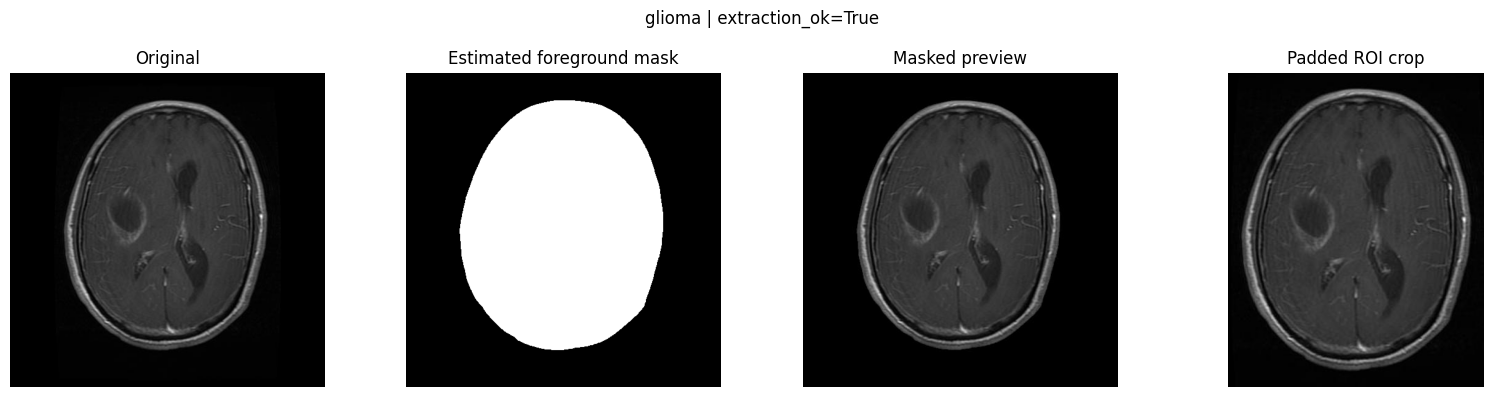

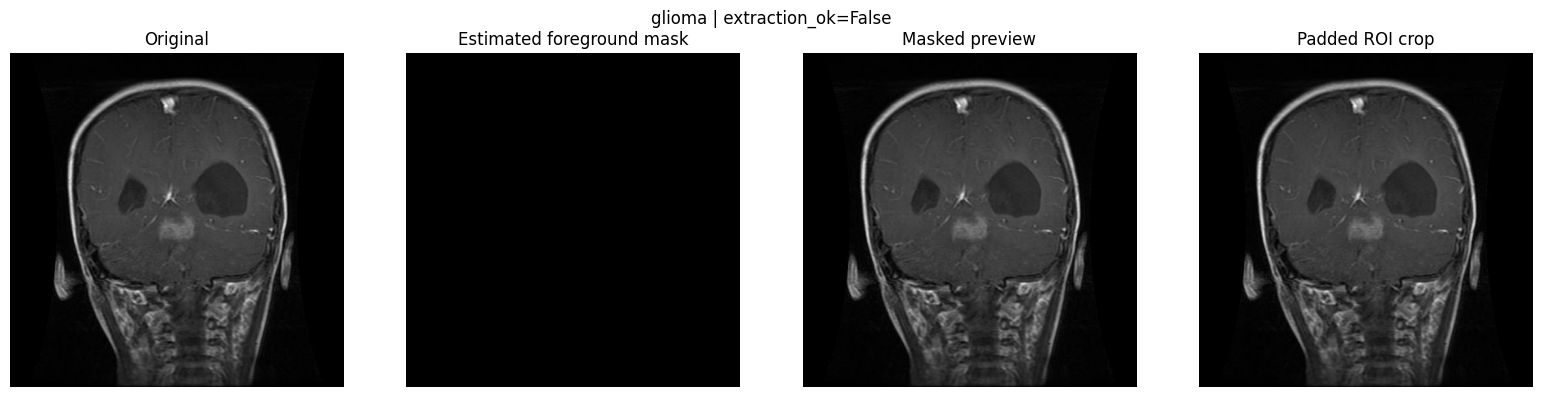

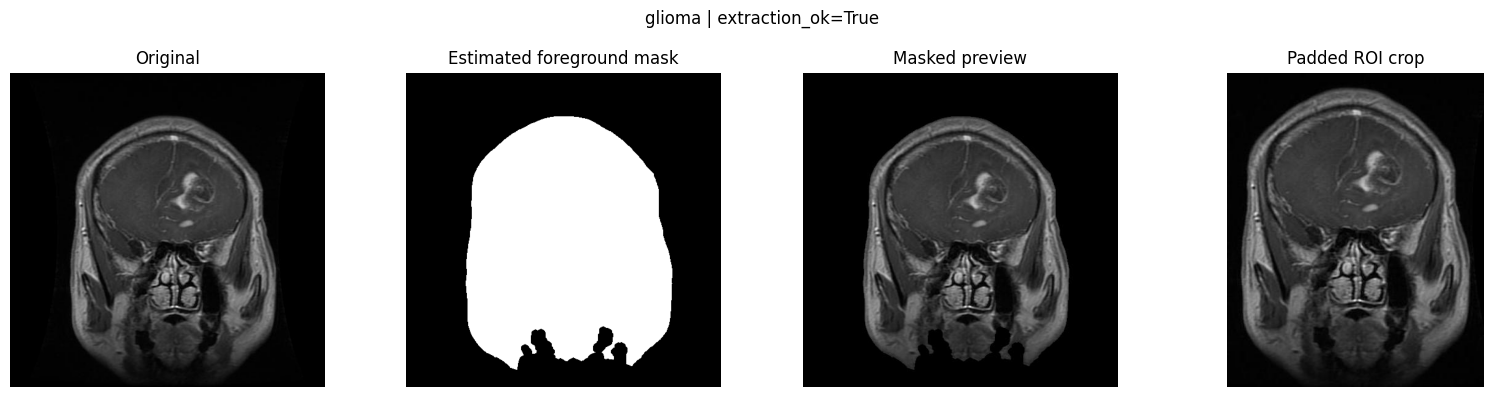

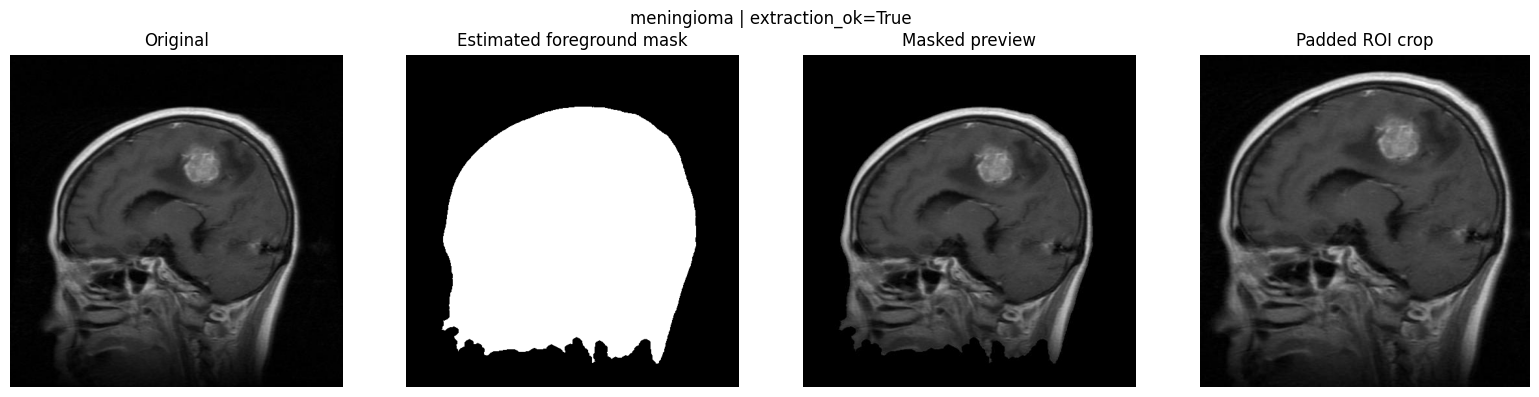

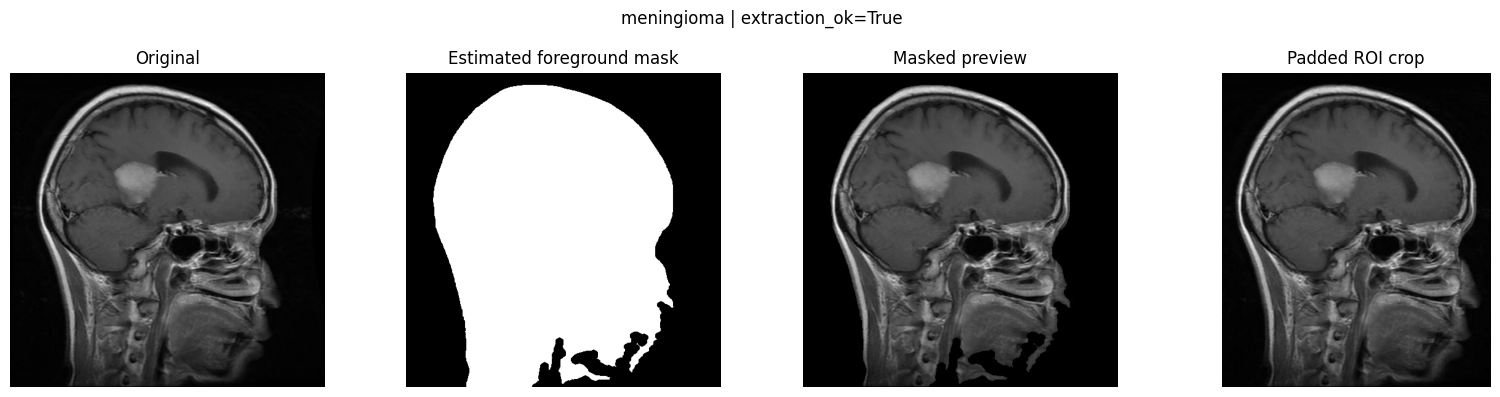

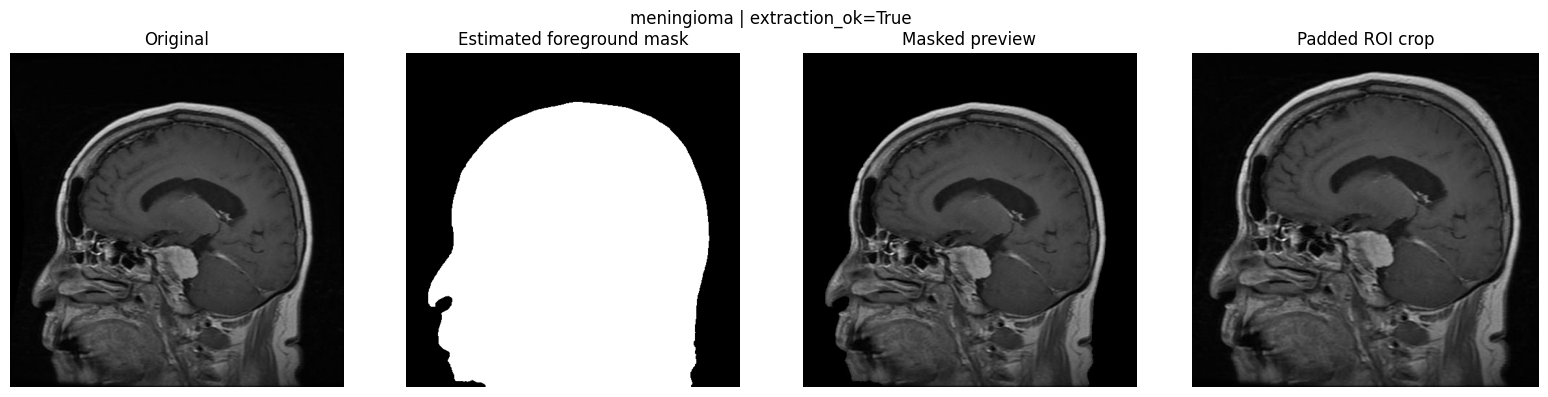

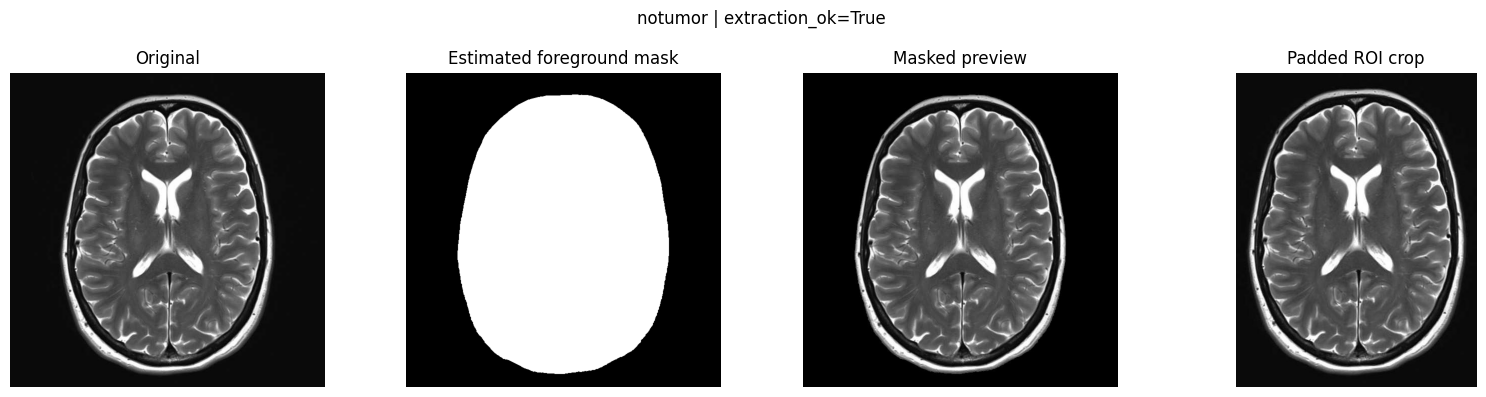

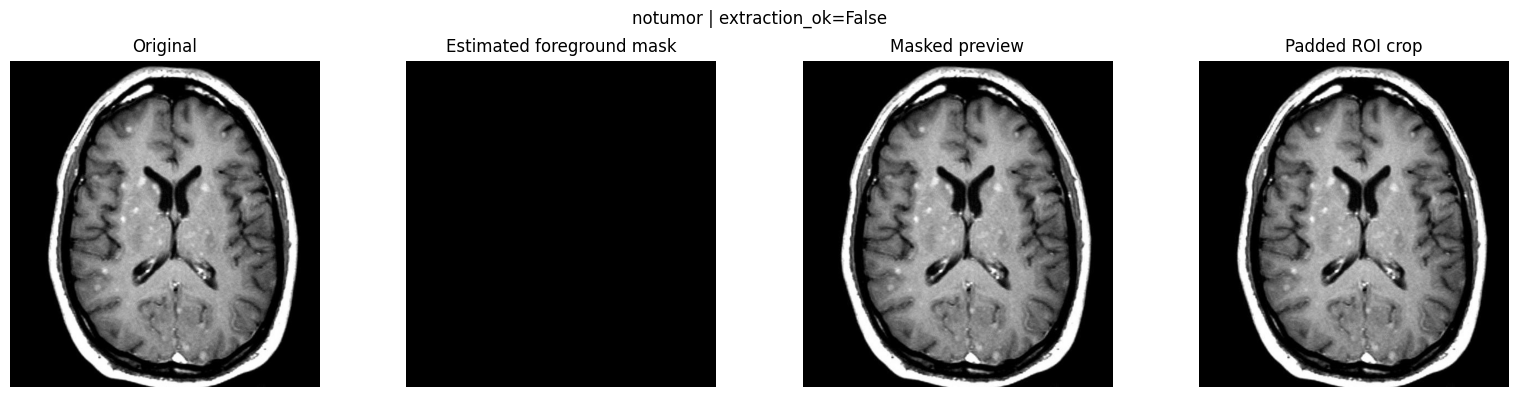

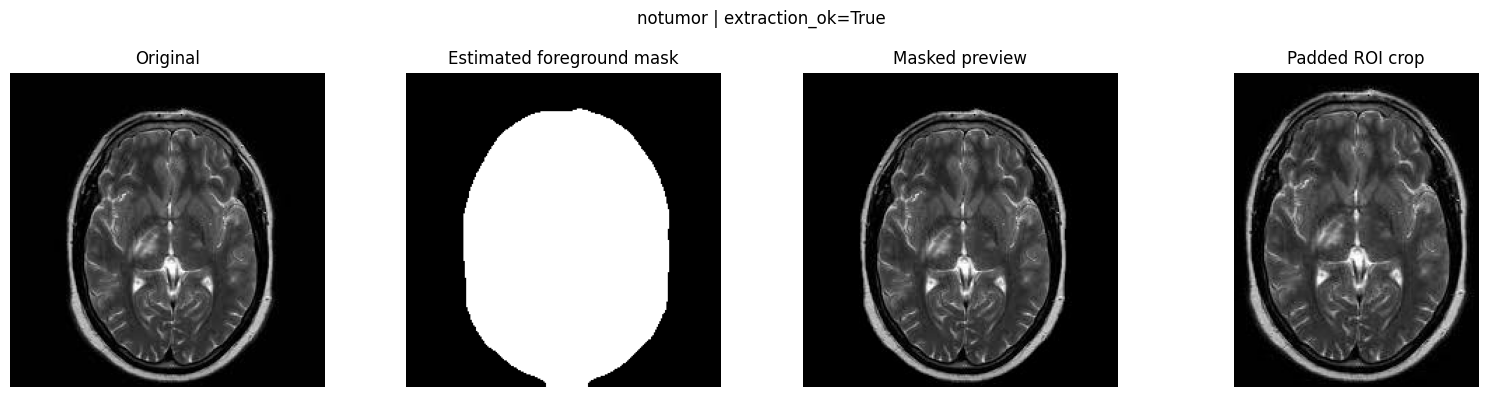

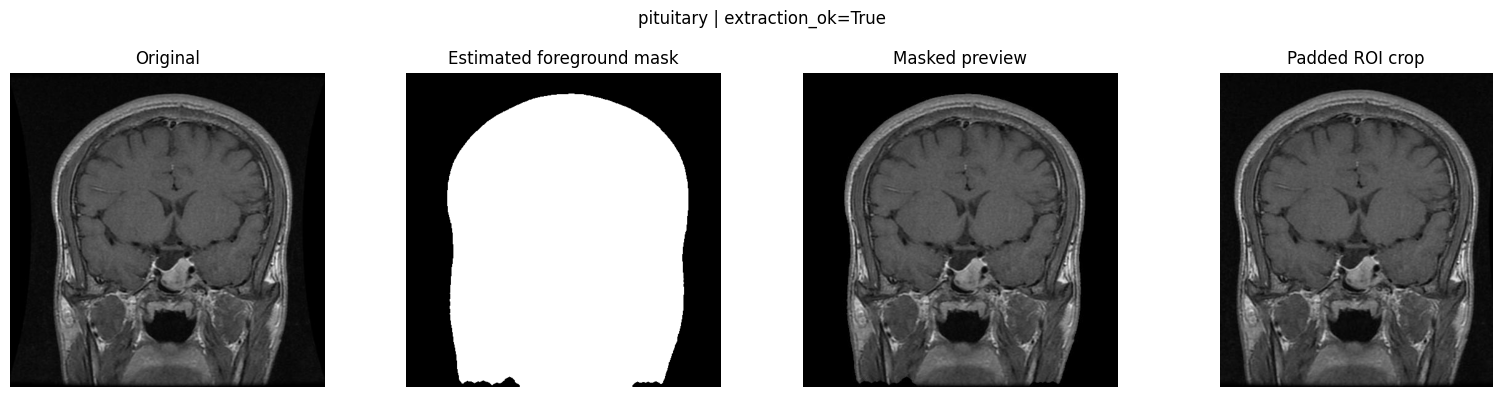

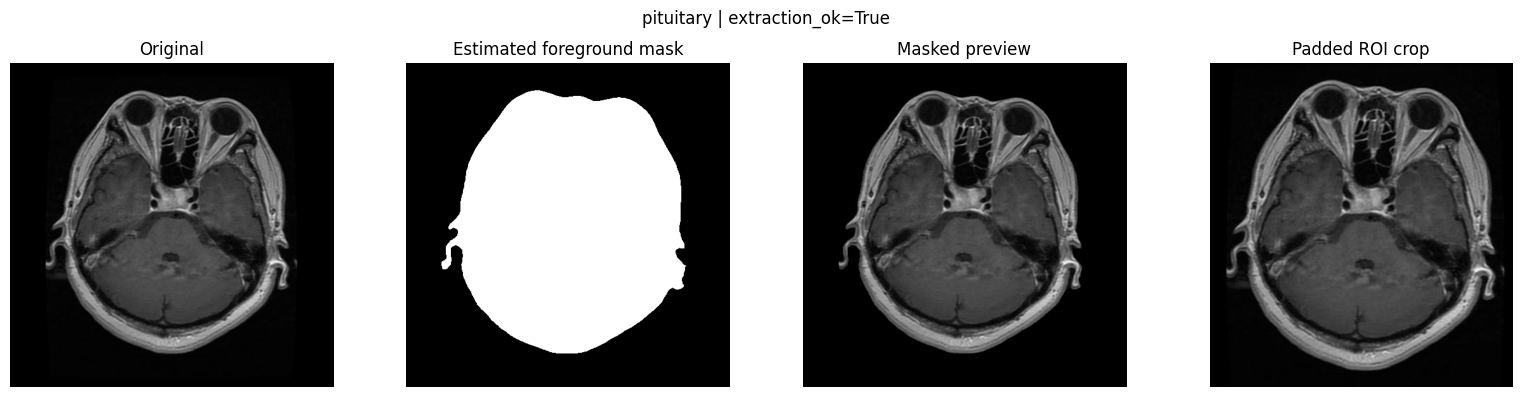

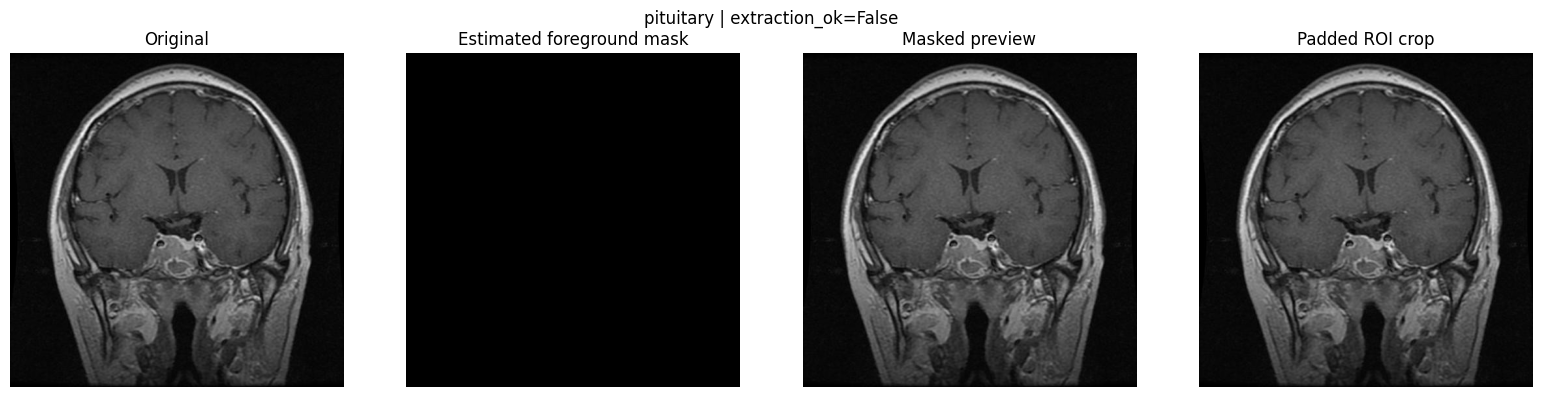

In [8]:
def visualize_samples(qc_dataframe, samples_per_class=3):
    rng = np.random.default_rng(SEED)

    for class_name in CLASS_NAMES:
        subset = qc_dataframe[
            (qc_dataframe["split"] == "Training") &
            (qc_dataframe["class_name"] == class_name)
        ]

        if subset.empty:
            continue

        chosen_indices = rng.choice(
            subset.index,
            size=min(samples_per_class, len(subset)),
            replace=False
        )

        for idx in chosen_indices:
            row = qc_dataframe.loc[idx]

            original = np.asarray(
                Image.open(row["source_path"]).convert("RGB")
            )
            crop = np.asarray(
                Image.open(row["cropped_path"]).convert("RGB")
            )

            masked_path = row.get("masked_path", "")
            if isinstance(masked_path, str) and masked_path and Path(masked_path).exists():
                masked = np.asarray(Image.open(masked_path).convert("RGB"))
            else:
                masked = original.copy()

            # Recreate mask for display only.
            mask, _ = extract_largest_foreground(original)
            if mask is None:
                mask_display = np.zeros(original.shape[:2], dtype=np.uint8)
            else:
                mask_display = mask

            fig, axes = plt.subplots(1, 4, figsize=(16, 4))
            axes[0].imshow(original)
            axes[0].set_title("Original")
            axes[1].imshow(mask_display, cmap="gray")
            axes[1].set_title("Estimated foreground mask")
            axes[2].imshow(masked)
            axes[2].set_title("Masked preview")
            axes[3].imshow(crop)
            axes[3].set_title("Padded ROI crop")

            for ax in axes:
                ax.axis("off")

            fig.suptitle(
                f"{class_name} | extraction_ok={row.get('extraction_ok', False)}"
            )
            plt.tight_layout()
            plt.show()

visualize_samples(qc_df, samples_per_class=3)

## Cell 9 — Inspect mask fraction distributions

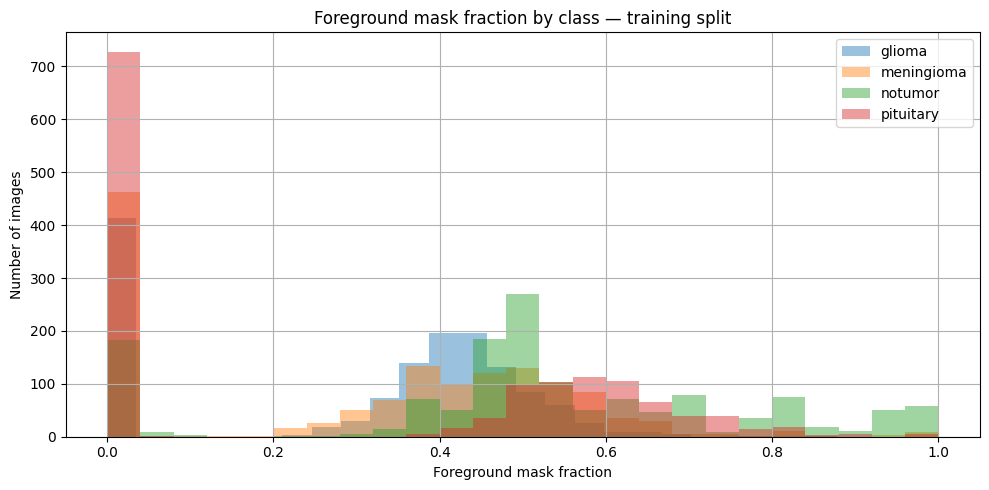

In [9]:
valid_qc = qc_df[qc_df["mask_fraction"].notna()].copy()

plt.figure(figsize=(10, 5))
for class_name in CLASS_NAMES:
    values = valid_qc.loc[
        (valid_qc["split"] == "Training") &
        (valid_qc["class_name"] == class_name),
        "mask_fraction"
    ].dropna()

    plt.hist(values, bins=25, alpha=0.45, label=class_name)

plt.xlabel("Foreground mask fraction")
plt.ylabel("Number of images")
plt.title("Foreground mask fraction by class — training split")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(QC_DIR / "mask_fraction_distribution.png", dpi=300)
plt.show()

## Cell 10 — Verify extracted dataset counts

In [10]:
count_rows = []

for split in SPLITS:
    for class_name in CLASS_NAMES:
        folder = CROPPED_ROOT / split / class_name
        count = sum(
            1 for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
        )
        count_rows.append({
            "split": split,
            "class_name": class_name,
            "image_count": count
        })

counts_df = pd.DataFrame(count_rows)
display(counts_df)

counts_df.to_csv(QC_DIR / "extracted_dataset_counts.csv", index=False)

,split,class_name,image_count
0,Training,glioma,1400
1,Training,meningioma,1400
2,Training,notumor,1400
3,Training,pituitary,1400
4,Testing,glioma,400
5,Testing,meningioma,400
6,Testing,notumor,400
7,Testing,pituitary,400


## Cell 11 — Save experiment configuration

In [11]:
config = {
    "experiment": "Notebook 04 - Classical foreground ROI extraction",
    "method": "Otsu threshold + morphological closing + largest connected component",
    "padding_fraction": PADDING_FRACTION,
    "morph_kernel_size": MORPH_KERNEL_SIZE,
    "minimum_mask_fraction": MIN_MASK_FRACTION,
    "maximum_mask_fraction": MAX_MASK_FRACTION,
    "classes": CLASS_NAMES,
    "splits": SPLITS,
    "primary_output": str(CROPPED_ROOT),
    "auxiliary_masked_output": str(MASKED_ROOT),
    "quality_report": str(qc_csv),
    "note": "ROI cropping is not validated medical skull stripping or tumor segmentation."
}

with open(QC_DIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Notebook 04 preprocessing completed.")
print("ROI-cropped dataset:", CROPPED_ROOT)
print("QC report:", qc_csv)

Notebook 04 preprocessing completed.
ROI-cropped dataset: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_04\roi_cropped
QC report: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_04\quality_control\roi_extraction_quality_report.csv


## Interpretation and decision gate

Before using these images in Notebook 05, answer:

1. Does the estimated foreground mask include the full brain/head region?
2. Are any tumor-containing regions visibly excluded?
3. Are the crops consistent across glioma, meningioma, no-tumor, and pituitary?
4. Are there many fallback images?
5. Does the method behave differently for images with different dimensions or backgrounds?

### Important decision

- If the ROI crops look sensible, use `roi_cropped` as the experimental input for Notebook 05.
- Do not use `masked_preview` for training unless visual inspection confirms it does not erase relevant anatomy.
- If masks fail on many images, do not force this method. We should choose a more suitable 2D foreground extraction strategy or a pretrained brain extraction method compatible with the source data.

### Limitations

This method cannot identify the true brain boundary reliably. It may include skull/scalp and may fail on unusual image backgrounds, annotations, or partial slices. It is an exploratory preprocessing experiment, not a clinically validated segmentation pipeline.